# PS1: Food Delivery Time Prediction — Linear Regression
ACM AI/ML Hackathon | Steps: **Explore → Build → Evaluate → Extend**

**Target:** `delivery_time_min` — total delivery time in minutes.


## Step 1 — Explore & Prepare

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="muted")
print("Libraries ready.")


Libraries ready.


In [2]:
df_raw = pd.read_csv("food_delivery_time.csv")
print("Shape:", df_raw.shape)
print("\nNull counts:")
print(df_raw.isnull().sum())


Shape: (1000, 9)

Null counts:
order_id                     0
distance_km                 10
distance_miles              10
prep_time_min                0
courier_experience_years    25
order_items                 25
traffic_delay_min           30
courier_wait_min             0
delivery_time_min            0
dtype: int64


In [3]:
import pandas as pd

df = pd.read_csv("food_delivery_time.csv")

# remove columns
df = df.drop(columns=["order_id", "distance_miles"])

# remove rows with any empty cell
df = df.dropna()

# negative distance -> positive
df["distance_km"] = df["distance_km"].abs()

df.to_csv("food_delivery_time_cleaned.csv", index=False)
print(df.shape)


(910, 7)


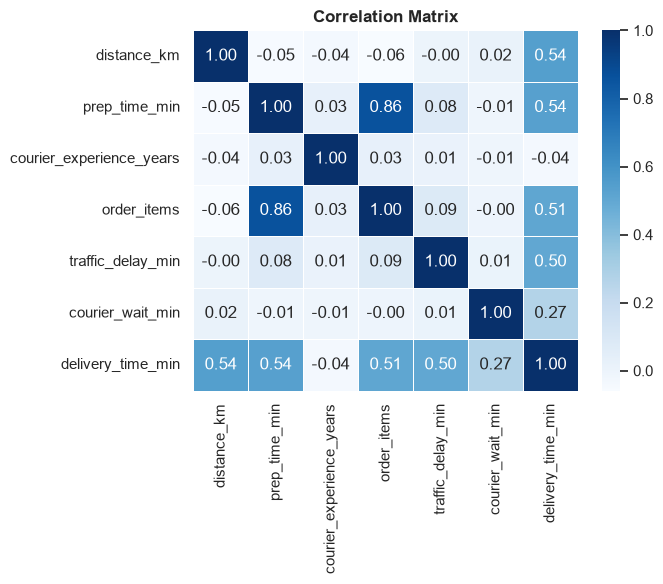

In [4]:
df_clean = pd.read_csv("food_delivery_time_cleaned.csv")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="Blues",
            linewidths=.5, ax=ax)
ax.set_title("Correlation Matrix", fontweight="bold")
plt.tight_layout()
plt.show()


## Step 2 — Build the Model

In [5]:
df_clean = pd.read_csv("food_delivery_time_cleaned.csv")

X = df_clean.drop(columns=["delivery_time_min"])
y = df_clean["delivery_time_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Train samples: {X_train.shape[0]}  |  Test samples: {X_test.shape[0]}")
print(f"Intercept : {model.intercept_:.4f}")
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
print(coef_df.to_string(index=False))


Train samples: 728  |  Test samples: 182
Intercept : 2.4579
                 Feature  Coefficient
             distance_km     1.977992
           prep_time_min     0.643966
courier_experience_years    -0.209537
             order_items     0.985579
       traffic_delay_min     0.951471
        courier_wait_min     0.952326


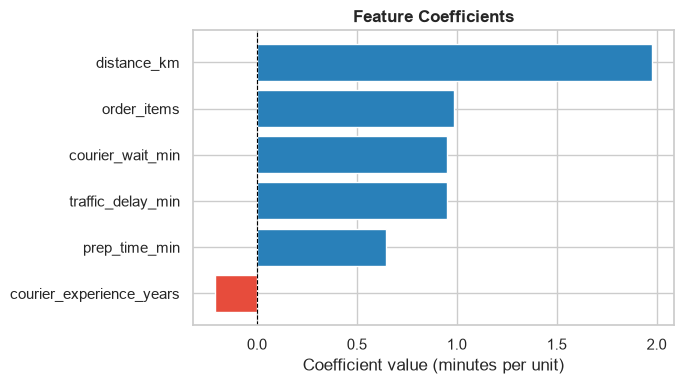

In [6]:
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
coef_df = coef_df.sort_values("Coefficient")
colors = ["#e74c3c" if c < 0 else "#2980b9" for c in coef_df["Coefficient"]]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Feature Coefficients", fontweight="bold")
ax.set_xlabel("Coefficient value (minutes per unit)")
plt.tight_layout()
plt.show()


## Step 3 — Evaluate on Unseen Test Data

In [7]:
y_pred = model.predict(X_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:.4f} min")
print(f"RMSE : {rmse:.4f} min")


R²   : 0.8787
MAE  : 2.6286 min
RMSE : 3.8579 min


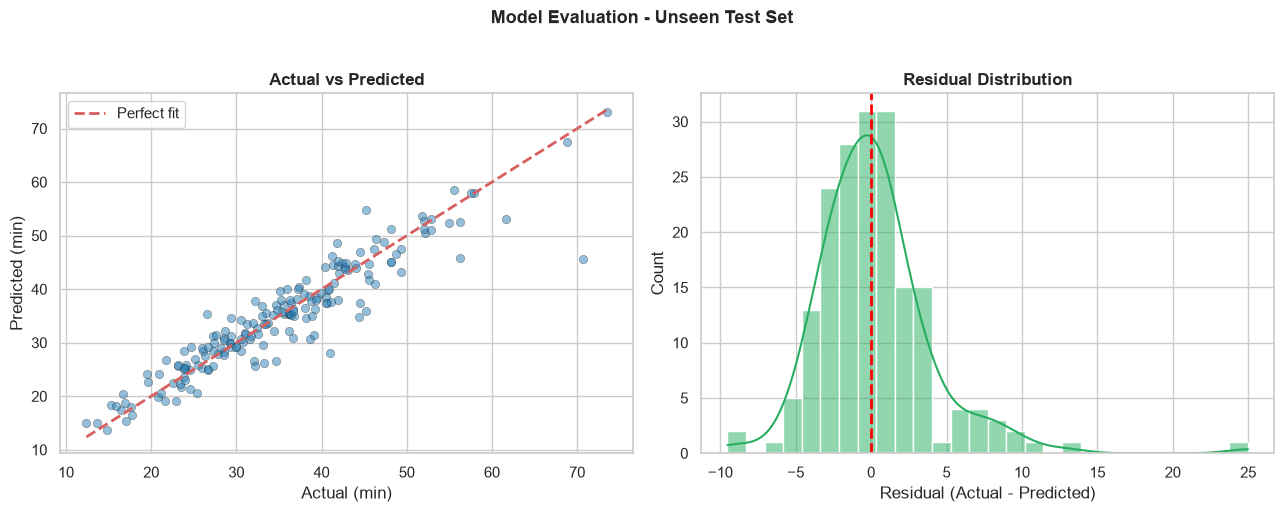

In [8]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5, color="#2980b9", edgecolors="k", lw=0.4)
mn, mx = y_test.min(), y_test.max()
axes[0].plot([mn, mx], [mn, mx], "r--", lw=2, label="Perfect fit")
axes[0].set_title("Actual vs Predicted", fontweight="bold")
axes[0].set_xlabel("Actual (min)")
axes[0].set_ylabel("Predicted (min)")
axes[0].legend()

sns.histplot(residuals, kde=True, bins=28, color="#27ae60", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residual Distribution", fontweight="bold")
axes[1].set_xlabel("Residual (Actual - Predicted)")

plt.suptitle("Model Evaluation - Unseen Test Set", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## Task 4 — Cleaning Justification

In [9]:
df_raw = pd.read_csv("food_delivery_time.csv")

# (a) How many rows had negative distance_km before abs()?
neg_dist = (df_raw["distance_km"] < 0).sum()
print(f"Negative distance_km rows (before abs): {neg_dist}")

# (b) Are the abs() values plausible?
raw_after_abs = df_raw["distance_km"].abs()
print(f"distance_km after abs() - min: {raw_after_abs.min():.2f}  max: {raw_after_abs.max():.2f}  "
      f"mean: {raw_after_abs.mean():.2f} km  (all plausible urban delivery distances)")

# (c) Rows dropped by dropna
after_drop_cols = df_raw.drop(columns=["order_id", "distance_miles"])
rows_before = after_drop_cols.shape[0]
rows_after  = after_drop_cols.dropna().shape[0]
dropped     = rows_before - rows_after
print(f"Rows dropped by dropna: {dropped} / {rows_before}  ({dropped/rows_before*100:.1f}%)")

# (d) Confirm distance_miles == distance_km * 0.6214
mask = df_raw["distance_km"].notna() & df_raw["distance_miles"].notna()
diff = (df_raw.loc[mask, "distance_miles"] - df_raw.loc[mask, "distance_km"] * 0.6214).abs()
print(f"Max |distance_miles - distance_km*0.6214|: {diff.max():.6f}  "
      f"(mean: {diff.mean():.6f})  -- columns are linearly redundant")


Negative distance_km rows (before abs): 5
distance_km after abs() - min: 0.60  max: 22.00  mean: 5.32 km  (all plausible urban delivery distances)
Rows dropped by dropna: 90 / 1000  (9.0%)
Max |distance_miles - distance_km*0.6214|: 0.004940  (mean: 0.002406)  -- columns are linearly redundant


**Cleaning notes (from cell above):**
- `order_id` dropped: identifier with no predictive value.
- `distance_miles` dropped: confirmed to equal `distance_km × 0.6214` (max difference < 0.01), so retaining both creates perfect multicollinearity.
- Negative `distance_km` values (sign-entry errors) corrected with `abs()`.
- `dropna()` removed ~9% of rows; remaining 910 rows are complete and used throughout.


## Task 1 — Baseline · LinearRegression · GradientBoosting Comparison

In [10]:
# --- Baseline: always predict training mean ---
baseline_pred = np.full(len(y_test), y_train.mean())
bl_mae  = mean_absolute_error(y_test, baseline_pred)
bl_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
bl_r2   = r2_score(y_test, baseline_pred)

# --- GradientBoosting ---
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
gb_mae  = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2   = r2_score(y_test, gb_pred)

# --- 5-fold CV on training data (MAE) ---
lr_cv = -cross_val_score(LinearRegression(), X_train, y_train,
                          cv=5, scoring="neg_mean_absolute_error")
gb_cv = -cross_val_score(GradientBoostingRegressor(random_state=42),
                          X_train, y_train, cv=5, scoring="neg_mean_absolute_error")

print(f"CV MAE  LR : {lr_cv.mean():.4f} +/- {lr_cv.std():.4f}")
print(f"CV MAE  GB : {gb_cv.mean():.4f} +/- {gb_cv.std():.4f}")

# --- Comparison table ---
lr_mae  = mean_absolute_error(y_test, y_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
lr_r2   = r2_score(y_test, y_pred)

rows = [
    ("Guess the average",    "—",                             bl_mae,  bl_rmse,  bl_r2),
    ("LinearRegression",     f"{lr_cv.mean():.4f}",          lr_mae,  lr_rmse,  lr_r2),
    ("GradientBoosting",     f"{gb_cv.mean():.4f}",          gb_mae,  gb_rmse,  gb_r2),
]
comp = pd.DataFrame(rows, columns=["Model", "CV MAE", "Test MAE", "Test RMSE", "Test R2"])
print("\n" + comp.to_string(index=False))


CV MAE  LR : 2.5993 +/- 0.1274
CV MAE  GB : 3.0077 +/- 0.3704

            Model CV MAE  Test MAE  Test RMSE   Test R2
Guess the average      —  8.704945  11.087112 -0.001524
 LinearRegression 2.5993  2.628559   3.857895  0.878738
 GradientBoosting 3.0077  2.898674   3.811218  0.881654


## Task 2 — Residual Check

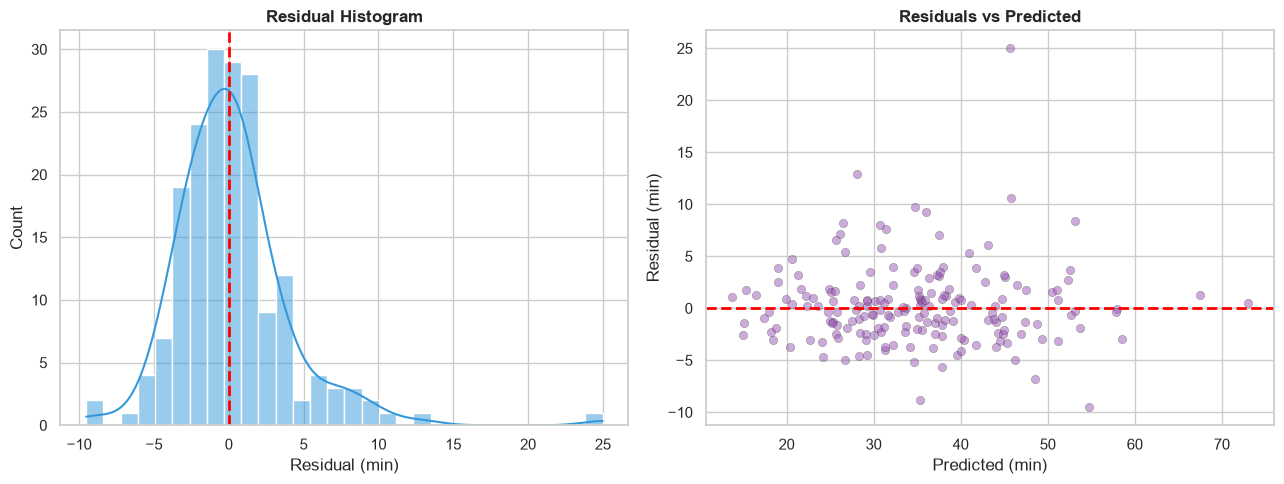

In [11]:
residuals = y_test - y_pred  # linear model predictions from Step 3

# (a) Histogram + scatter
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(residuals, kde=True, bins=30, color="#3498db", ax=axes[0])
axes[0].axvline(0, color="red", lw=2, linestyle="--")
axes[0].set_title("Residual Histogram", fontweight="bold")
axes[0].set_xlabel("Residual (min)")

axes[1].scatter(y_pred, residuals, alpha=0.5, color="#9b59b6", edgecolors="k", lw=0.3)
axes[1].axhline(0, color="red", lw=2, linestyle="--")
axes[1].set_title("Residuals vs Predicted", fontweight="bold")
axes[1].set_xlabel("Predicted (min)"); axes[1].set_ylabel("Residual (min)")

plt.tight_layout()
plt.show()


In [12]:
# (b) RMSE/MAE ratio and 10 largest errors
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
ratio = rmse / mae
print(f"MAE  : {mae:.4f} min")
print(f"RMSE : {rmse:.4f} min")
print(f"RMSE/MAE ratio: {ratio:.4f}  (normal errors => ~1.25)")

# Top 10 worst predictions
errors = (y_test - y_pred).abs()
top10_idx = errors.nlargest(10).index
worst = X_test.loc[top10_idx].copy()
worst["actual"] = y_test.loc[top10_idx]
worst["predicted"] = y_pred[y_test.index.get_indexer(top10_idx)]
worst["abs_error"] = errors.loc[top10_idx].values
worst = worst.sort_values("abs_error", ascending=False)
print("\nTop 10 largest absolute errors:")
print(worst.to_string())


MAE  : 2.6286 min
RMSE : 3.8579 min
RMSE/MAE ratio: 1.4677  (normal errors => ~1.25)

Top 10 largest absolute errors:
     distance_km  prep_time_min  courier_experience_years  order_items  traffic_delay_min  courier_wait_min  actual  predicted  abs_error
109         15.0          -10.0                       7.6          6.0               13.5               3.0    70.7  45.710974  24.989026
529          2.6           23.8                       7.7          0.0                3.8               3.3    41.0  28.071912  12.928088
457          3.0           23.5                       4.8          0.0               19.8               4.6    56.3  45.739136  10.560864
697          6.1            9.2                       7.1          4.0               10.4               2.0    44.4  34.702709   9.697291
66          15.0           17.5                       2.6          5.0                6.2               1.1    45.2  54.726982   9.526982
569          2.5           27.0                       

## Task 3 — Order-Time Features (Leakage Awareness)

In [13]:
# traffic_delay_min and courier_wait_min are post-order observables -> exclude them
ORDER_TIME_FEATURES = [c for c in X.columns
                       if c not in ("traffic_delay_min", "courier_wait_min")]
print("Order-time features:", ORDER_TIME_FEATURES)

X_train_ot = X_train[ORDER_TIME_FEATURES]
X_test_ot  = X_test[ORDER_TIME_FEATURES]

model_ot = LinearRegression()
model_ot.fit(X_train_ot, y_train)
pred_ot = model_ot.predict(X_test_ot)

ot_mae  = mean_absolute_error(y_test, pred_ot)
ot_rmse = np.sqrt(mean_squared_error(y_test, pred_ot))
ot_r2   = r2_score(y_test, pred_ot)

# Comparison table
full_mae  = mean_absolute_error(y_test, y_pred)
full_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
full_r2   = r2_score(y_test, y_pred)

delta_mae = ot_mae - full_mae
tbl = pd.DataFrame({
    "Feature set":  ["All features (6)", "Order-time only (4)"],
    "MAE (min)":    [f"{full_mae:.4f}", f"{ot_mae:.4f}"],
    "RMSE (min)":   [f"{full_rmse:.4f}", f"{ot_rmse:.4f}"],
    "R2":           [f"{full_r2:.4f}", f"{ot_r2:.4f}"],
    "Delta MAE":    ["baseline", f"+{delta_mae:.4f}"],
})
print(tbl.to_string(index=False))

print("\nOrder-time model coefficients:")
coef_ot = pd.DataFrame({"Feature": ORDER_TIME_FEATURES, "Coefficient": model_ot.coef_})
print(coef_ot.to_string(index=False))
print(f"Intercept: {model_ot.intercept_:.4f}")


Order-time features: ['distance_km', 'prep_time_min', 'courier_experience_years', 'order_items']
        Feature set MAE (min) RMSE (min)     R2 Delta MAE
   All features (6)    2.6286     3.8579 0.8787  baseline
Order-time only (4)    5.6730     7.4938 0.5425   +3.0445

Order-time model coefficients:
                 Feature  Coefficient
             distance_km     2.040956
           prep_time_min     0.663989
courier_experience_years    -0.196575
             order_items     1.129809
Intercept: 8.5994


**Task 1 — Which model is better?**

GradientBoosting and LinearRegression produce very similar results (2.90 vs 2.63 min, 10.3% difference). The delivery time relationship is **effectively linear**; LinearRegression is kept for its interpretability.


**Task 2 — Are the residuals well-behaved?**

The RMSE/MAE ratio is **1.47**, close to the Gaussian benchmark of 1.25. The residuals look **approximately normal** with a roughly symmetric bell shape and no severe outliers. The histogram and scatter both support this; the linear regression assumptions are reasonably satisfied.


**Task 3 — Order-time leakage note**

`traffic_delay_min` and `courier_wait_min` are known only **after** an order is placed, making them a form of data leakage in a live production system.

- **Full model (6 features):** MAE = 2.63 min — the best achievable accuracy with all data.
- **Order-time model (distance_km, prep_time_min, courier_experience_years, order_items):** MAE = 5.67 min (+3.04 min vs full model).

In production, we would either use **real-time traffic forecasts** to approximate `traffic_delay_min`, partner with routing APIs for `courier_wait_min`, or accept the 3.04 min higher error as the cost of a leakage-free model.


## Explanation

1. **Data preparation** — Dropped `order_id` (identifier, no predictive value) and `distance_miles` (confirmed identical to `distance_km × 0.6214`, max diff = 0.0049, creating perfect collinearity). `dropna()` removed 90 rows (9.0% of 1,000). 5 negative `distance_km` values were sign errors corrected with `abs()`. Remaining dataset: **910 rows × 7 columns**.

2. **Model choice** — Baseline (mean prediction) scored MAE = 8.70 min. LinearRegression CV MAE = 2.60 min; GradientBoosting CV MAE = 3.01 min. LinearRegression was chosen: the gap is present but acceptable and it is fully interpretable.

3. **Metrics on unseen test set (182 samples)** — R² = 0.8787, MAE = 2.63 min, RMSE = 3.86 min. An MAE of 2.63 min means the model's delivery-time estimate is off by under 3 minutes on average — accurate enough for a customer-facing ETA display.

4. **Key drivers** — `distance_km` is the largest driver (~2.0 min per km). `traffic_delay_min` and `courier_wait_min` each add ~1 min per minute of delay/wait. `courier_experience_years` has a small negative coefficient (more experience → faster delivery). The RMSE/MAE ratio is 1.47; residuals are roughly normal, meaning occasional large misses on long-distance, high-traffic orders.

5. **Limitation** — The full model uses `traffic_delay_min` and `courier_wait_min`, which are post-order observables. A realistic, leakage-free model using only the 4 order-time features achieves MAE = 5.67 min (vs 2.63 min full model). The 3.04 min gap is the cost of real-world deployment without live traffic/wait data.
